In [ ]:
import pandas as pd
import numpy as np
import joblib
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score, mean_absolute_error

### Overall Model Comparison

The March 2026 validation results from the baseline, feature-engineered, and advanced models are loaded from the CSV files generated in Notebooks (04_model_comparison.ipynb and 05_advanced_models.ipynb) and combined into a single comparison table.

Models are compared using R², MAE, MAPE, and MdAPE on the original closing-price scale to identify the strongest candidates for final evaluation on the April 2026 test dataset.

In [2]:
# Load March 2026 validation results
baseline_results = pd.read_csv("../results/validation_results_march_2026.csv")

advanced_results = pd.read_csv("../results/advanced_validation_results_march_2026.csv")

# Combine model results
validation_comparison = pd.concat([baseline_results, advanced_results], ignore_index=True)
display(validation_comparison.round(4))

,Model,Training R²,Validation R²,Validation MAE ($),Validation MAPE (%),Validation MdAPE (%)
0,Linear Regression,0.8179,0.7969,210747.5800,15.8204,12.0141
1,Default Decision Tree,0.9560,0.7863,215217.8068,16.1685,10.7692
2,Regularized Decision Tree,0.8989,0.8490,186007.8322,13.7512,9.5891
3,Random Forest,0.9648,0.8826,157066.8146,11.4503,7.7477
4,Linear Regression + Ratio,0.8145,0.7891,209442.1398,15.6720,11.7796
5,Decision Tree + Ratio,0.8989,0.8459,187440.0296,13.8286,9.5567
6,Random Forest + Ratio,0.9650,0.8826,156888.2770,11.4464,7.7208
7,Linear Regression + School Districts,0.8198,0.7967,208924.5050,15.6519,11.8946
8,Decision Tree + School Districts,0.9016,0.8544,183277.6838,13.5947,9.3744
9,Random Forest + School Districts,0.9640,0.8851,155320.1898,11.3620,7.6808


In [3]:
# Save March 2026 validation results
validation_comparison.to_csv("../results/combined_validation_results_march_2026.csv", index=False)

### Top 10 Model Performance

The ten models with the highest March 2026 validation R² are selected from the combined results. Their R², MAE, MAPE, and MdAPE are compared to identify the strongest-performing configurations.

Validation R² is also visualized to highlight differences in predictive performance among the top models.

In [ ]:
# Sort by validation R²
validation_comparison = validation_comparison.sort_values("Validation R²", ascending=False)

# Select top 10 models based on validation R²
top_models_df = validation_comparison.head(10).copy()

# Display selected metrics
display(top_models_df[["Model", "Validation R²", "Validation MAE ($)", "Validation MAPE (%)", "Validation MdAPE (%)"]].round(4))

,Model,Validation R²,Validation MAE ($),Validation MAPE (%),Validation MdAPE (%)
39,Tuned XGBoost + School Districts + HOA + Flooring,0.9092,141842.2229,10.5133,7.3650
31,XGBoost + Comparable Sales,0.8967,153881.0114,11.6015,8.2839
33,XGBoost + Flooring,0.8948,155012.1297,11.5186,8.2031
37,XGBoost + School Districts + HOA + Flooring,0.8947,153959.7640,11.4114,8.1514
29,XGBoost + HOA,0.8940,155218.7345,11.5801,8.1917
23,XGBoost,0.8934,156589.1681,11.6534,8.2339
25,XGBoost + Ratio,0.8933,157253.7670,11.7818,8.3757
27,XGBoost + School Districts,0.8932,156261.9767,11.6801,8.3810
35,XGBoost + Ratio + School Districts,0.8919,156612.0153,11.6909,8.3541
32,LightGBM + Comparable Sales,0.8877,161894.1207,12.1498,8.7626


The tuned XGBoost model demonstrated the strongest validation performance and was selected for further comparison with Random Forest across property price ranges.

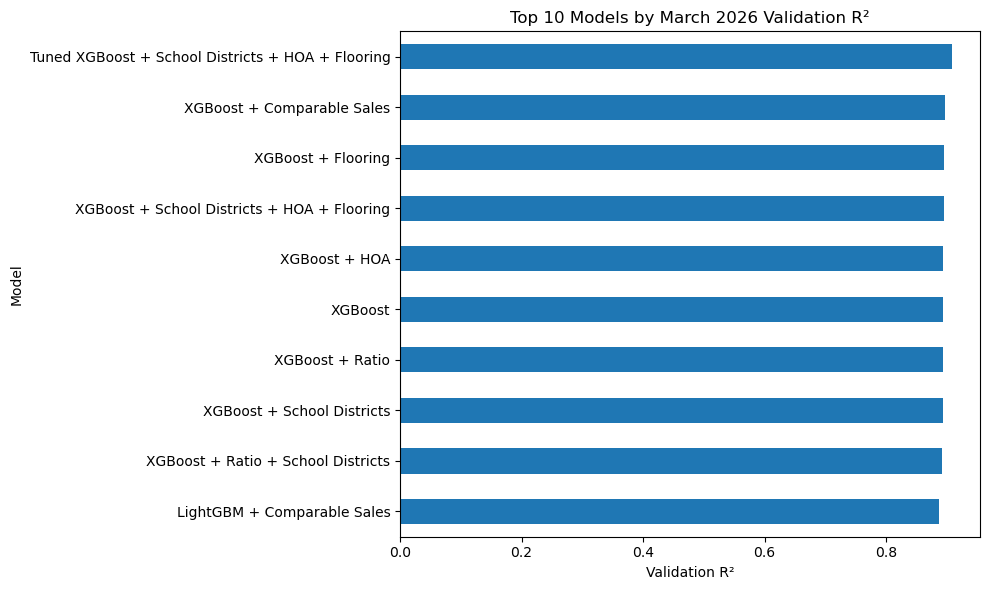

In [ ]:
# Plot validation R² for the top 10 models
ax = top_models_df.sort_values("Validation R²").plot(x="Model", y="Validation R²", kind="barh", figsize=(10, 6), legend=False)

ax.set_title("Top 10 Models by March 2026 Validation R²")
ax.set_xlabel("Validation R²")
ax.set_ylabel("Model")
plt.tight_layout()
plt.show()

### Validation Prediction Comparison

The saved March 2026 validation predictions from the selected Random Forest and tuned XGBoost models are loaded for further evaluation. Both models are compared using the same validation dataset to examine prediction errors across different property price ranges without retraining the models.

In [7]:
# Load Random Forest validation predictions
rf_predictions = pd.read_csv("../results/best_rf_validation_predictions.csv")

# Load tuned XGBoost validation predictions
xgb_predictions = pd.read_csv("../results/best_tuned_xgboost_validation_predictions.csv")

print("Random Forest:", rf_predictions.shape)
print("Tuned XGBoost:", xgb_predictions.shape)
display(rf_predictions.head())
display(xgb_predictions.head())

Random Forest: (11390, 2)
Tuned XGBoost: (11390, 2)


,Actual ClosePrice,Predicted ClosePrice
0,1370000.0,1.616207e+06
1,7200000.0,4.947534e+06
2,1240000.0,1.195813e+06
3,2650000.0,2.082278e+06
4,830000.0,8.292504e+05


,Actual ClosePrice,Predicted ClosePrice
0,1370000.0,1644923.0
1,7200000.0,4422026.0
2,1240000.0,1185592.5
3,2650000.0,2070625.2
4,830000.0,822268.5


In [8]:
# Calculate Mean Absolute Percentage Error
def mape(y_true, y_pred):
    return np.mean(np.abs((y_true - y_pred) / y_true)) * 100

# Calculate Median Absolute Percentage Error
def mdape(y_true, y_pred):
    return np.median(np.abs((y_true - y_pred) / y_true)) * 100

# Define property price ranges
price_bins = [0, 500000, 1000000, 2000000, 4000000, np.inf]

price_labels = ["Under $500K", "$500K–$1M", "$1M–$2M", "$2M–$4M", "$4M+"]

# Calculate price-band performance for both models
price_band_results = []

for model_name, predictions_df in [("Random Forest", rf_predictions), ("Tuned XGBoost", xgb_predictions)]:

    df = predictions_df.copy()
    df["Price Range"] = pd.cut(df["Actual ClosePrice"], bins=price_bins, labels=price_labels, right=False)

    for price_range, group in df.groupby("Price Range", observed=True):

        actual = group["Actual ClosePrice"]
        predicted = group["Predicted ClosePrice"]

        price_band_results.append({"Model": model_name, "Price Range": price_range, "Count": len(group),
                                   "R²": r2_score(actual, predicted) if len(group) >= 2 else np.nan,
                                   "MAPE (%)": mape(actual, predicted), "MdAPE (%)": mdape(actual, predicted)})
# Create comparison DataFrame
price_band_comparison_df = pd.DataFrame(price_band_results)
display(price_band_comparison_df.round(4))

,Model,Price Range,Count,R²,MAPE (%),MdAPE (%)
0,Random Forest,Under $500K,1635,0.0761,12.9290,7.2757
1,Random Forest,$500K–$1M,4908,0.4490,8.8098,5.9493
2,Random Forest,$1M–$2M,3361,0.2098,11.8384,9.0596
3,Random Forest,$2M–$4M,1221,-0.0252,14.5621,11.4114
4,Random Forest,$4M+,265,-0.9014,21.3925,19.3859
5,Tuned XGBoost,Under $500K,1635,0.1791,12.0920,7.1367
6,Tuned XGBoost,$500K–$1M,4908,0.5017,8.3888,5.7816
7,Tuned XGBoost,$1M–$2M,3361,0.3523,11.1244,8.8637
8,Tuned XGBoost,$2M–$4M,1221,0.1669,13.4512,10.9029
9,Tuned XGBoost,$4M+,265,-0.4775,18.8362,16.9654


### Key Findings (Price-Band Comparison)

* Overall Performance: Tuned XGBoost achieved lower MdAPE than Random Forest across all five property price ranges.

* Best Performance: Both models performed best for properties priced between `$500K - $1M`, with tuned XGBoost achieving a MdAPE of `5.78%`.

* Higher-Priced Properties: Prediction errors increased for properties above `$2M`, with the highest errors observed for homes priced above `$4M.`

* Expensive Properties: Tuned XGBoost reduced MdAPE for properties above $4M from approximately `19.39%` (Random Forest) to `16.97%`.

Overall, tuned XGBoost demonstrated better typical prediction accuracy across all price ranges, although high-priced properties remained the most challenging to predict.

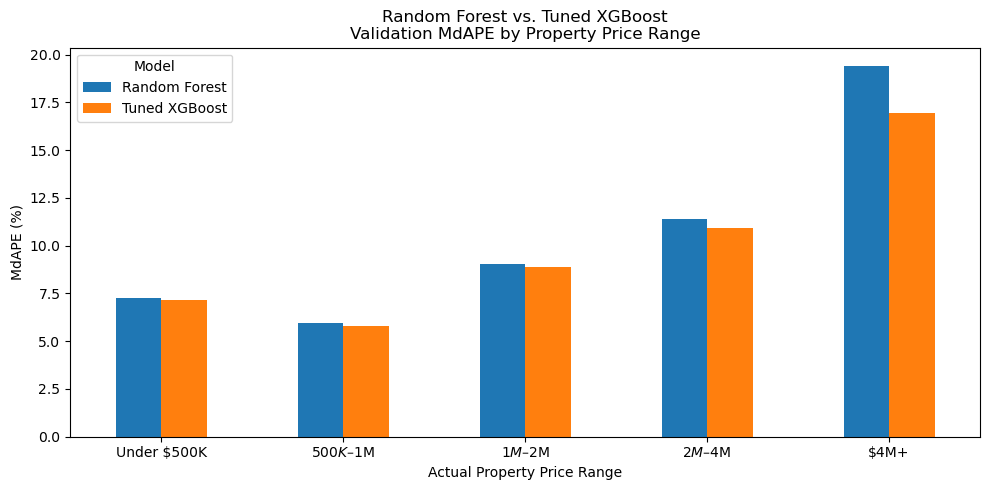

In [10]:
# Compare validation MdAPE across property price ranges
ax = price_band_comparison_df.pivot(index="Price Range", columns="Model",values="MdAPE (%)").\
    reindex(price_labels).plot(kind="bar", figsize=(10, 5), rot=0)

ax.set_title("Random Forest vs. Tuned XGBoost\nValidation MdAPE by Property Price Range")
ax.set_xlabel("Actual Property Price Range")
ax.set_ylabel("MdAPE (%)")
ax.legend(title="Model")

plt.tight_layout()
plt.show()

### Next Steps (Final Test Evaluation)

Following the team review and finalization of feature engineering, the selected Random Forest and tuned XGBoost models will be evaluated on the held-out April 2026 test dataset.

The test data will undergo the same cleaning, feature engineering, and preprocessing steps used during training and validation. The previously saved fitted pipelines will be loaded using joblib to generate test predictions without retraining.

Final performance will be assessed using R², MAE, MAPE, and MdAPE, including prediction errors across different property price ranges. The results will be saved as metrics_summary.csv.